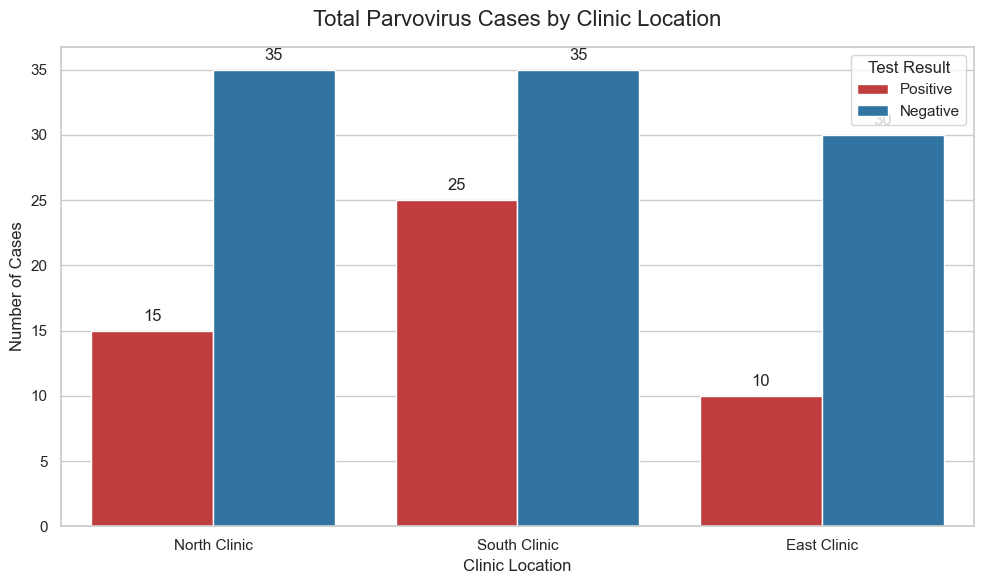

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Create the mock test-data
data = {
    'Clinic_Location': ['North Clinic']*50 + ['South Clinic']*60 + ['East Clinic']*40,
    'Parvovirus_Status': (
        ['Positive']*15 + ['Negative']*35 +  # North Clinic: 15 Pos, 35 Neg
        ['Positive']*25 + ['Negative']*35 +  # South Clinic: 25 Pos, 35 Neg
        ['Positive']*10 + ['Negative']*30    # East Clinic: 10 Pos, 30 Neg
    )
}
df = pd.DataFrame(data)

# 2. Set up the visualization style
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")
custom_palette = {"Positive": "#d62728", "Negative": "#1f77b4"} # Red for positive, Blue for negative

# 3. Create the grouped bar chart
ax = sns.countplot(
    data=df, 
    x='Clinic_Location', 
    hue='Parvovirus_Status',
    palette=custom_palette
)

# 4. Customize labels and titles
plt.title('Total Parvovirus Cases by Clinic Location', fontsize=16, pad=15)
plt.xlabel('Clinic Location', fontsize=12)
plt.ylabel('Number of Cases', fontsize=12)
plt.legend(title='Test Result', loc='upper right')

# Add value labels on top of the bars
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height)}', 
                    (p.get_x() + p.get_width() / 2., height), 
                    ha='center', va='bottom', 
                    xytext=(0, 5), textcoords='offset points')

# 5. Display the plot
plt.tight_layout()
plt.show()

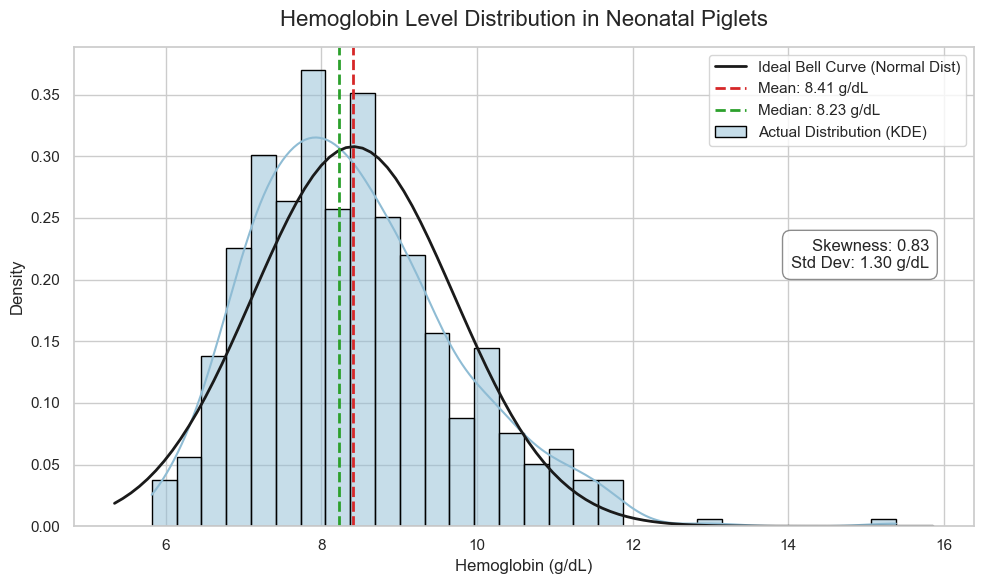

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skewnorm, norm, skew

# 1. Generate test data: Hemoglobin levels (g/dL) in neonatal piglets
# We use skewnorm to simulate real-world biological data with a slight positive skew
np.random.seed(42)
# Average neonatal piglet Hb is often around 7-10 g/dL
simulated_hb = skewnorm.rvs(a=3, loc=7.0, scale=2.0, size=500) 
df = pd.DataFrame({'Hemoglobin_g_dL': simulated_hb})

# 2. Calculate statistical metrics
hb_data = df['Hemoglobin_g_dL']
mean_val = hb_data.mean()
median_val = hb_data.median()
std_dev = hb_data.std()
skewness_val = skew(hb_data)

# 3. Set up the visualization
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Plot histogram with Kernel Density Estimate (KDE) representing the actual data distribution
sns.histplot(
    hb_data, 
    bins=30, 
    kde=True, 
    stat="density", 
    color="#8fbcd4", 
    edgecolor='black',
    label="Actual Distribution (KDE)"
)

# 4. Plot the ideal Bell Curve (Normal Distribution) overlay for comparison
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = norm.pdf(x, mean_val, std_dev)
plt.plot(x, p, 'k', linewidth=2, linestyle='-', label="Ideal Bell Curve (Normal Dist)")

# 5. Add reference lines to visualize skewness (Mean vs Median shift)
plt.axvline(mean_val, color='#d62728', linestyle='dashed', linewidth=2, 
            label=f'Mean: {mean_val:.2f} g/dL')
plt.axvline(median_val, color='#2ca02c', linestyle='dashed', linewidth=2, 
            label=f'Median: {median_val:.2f} g/dL')

# 6. Add contextual annotations and styling
plt.title('Hemoglobin Level Distribution in Neonatal Piglets', fontsize=16, pad=15)
plt.xlabel('Hemoglobin (g/dL)', fontsize=12)
plt.ylabel('Density', fontsize=12)

# Information box highlighting the skewness and spread
stats_text = f'Skewness: {skewness_val:.2f}\nStd Dev: {std_dev:.2f} g/dL'
plt.text(0.95, 0.6, stats_text, 
         transform=plt.gca().transAxes, 
         fontsize=12,
         verticalalignment='top', 
         horizontalalignment='right',
         bbox=dict(boxstyle='round,pad=0.5', facecolor='white', edgecolor='gray', alpha=0.9))

plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

C:\Users\simas\AppData\Local\Temp\ipykernel_396\1068839517.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


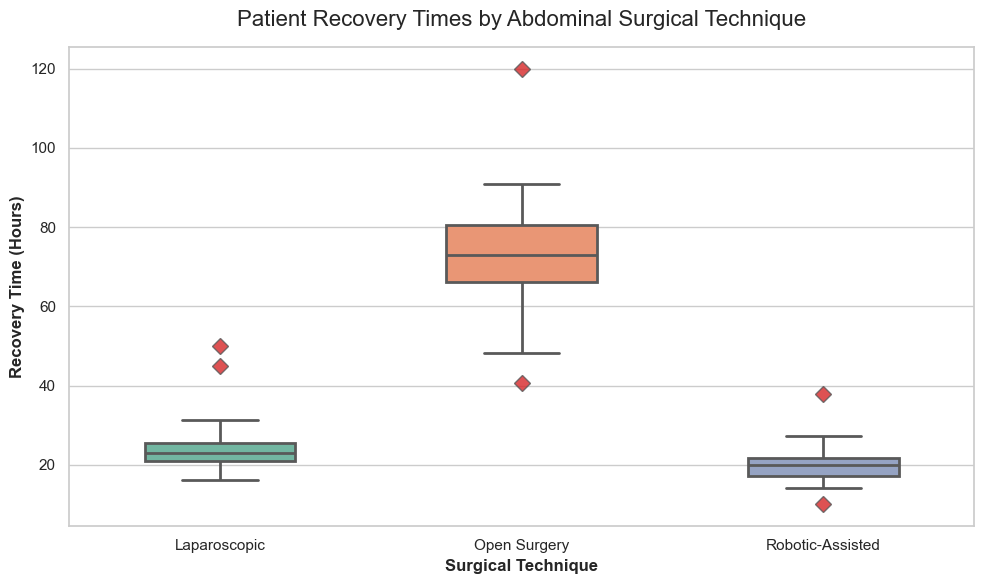

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Generate test data: Recovery times (hours) across 3 abdominal surgical techniques
np.random.seed(42)

# Laparoscopic: Generally fast recovery, tight spread, a couple of late-recovery outliers
laparoscopic = np.random.normal(loc=24, scale=4, size=50).tolist() + [45, 50] 

# Open Surgery: Longer baseline recovery, wider variance, one extreme outlier
open_surgery = np.random.normal(loc=72, scale=12, size=50).tolist() + [120]

# Robotic-Assisted: Fastest recovery, very consistent, one early and one late outlier
robotic = np.random.normal(loc=20, scale=3, size=50).tolist() + [10, 38]

# Combine into a single DataFrame
df = pd.DataFrame({
    'Surgical_Technique': (
        ['Laparoscopic'] * len(laparoscopic) + 
        ['Open Surgery'] * len(open_surgery) + 
        ['Robotic-Assisted'] * len(robotic)
    ),
    'Recovery_Time_Hours': laparoscopic + open_surgery + robotic
})

# 2. Set up the visualization style
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# 3. Create the box plot
# 'flierprops' is used to specifically highlight the outliers in red diamonds
sns.boxplot(
    data=df, 
    x='Surgical_Technique', 
    y='Recovery_Time_Hours',
    palette="Set2",
    width=0.5,
    linewidth=2,
    flierprops={"marker": "D", "markerfacecolor": "#d62728", "markersize": 8, "alpha": 0.8}
)

# 4. Customize labels and title
plt.title('Patient Recovery Times by Abdominal Surgical Technique', fontsize=16, pad=15)
plt.xlabel('Surgical Technique', fontsize=12, fontweight='bold')
plt.ylabel('Recovery Time (Hours)', fontsize=12, fontweight='bold')

# 5. Display the plot
plt.tight_layout()
plt.show()

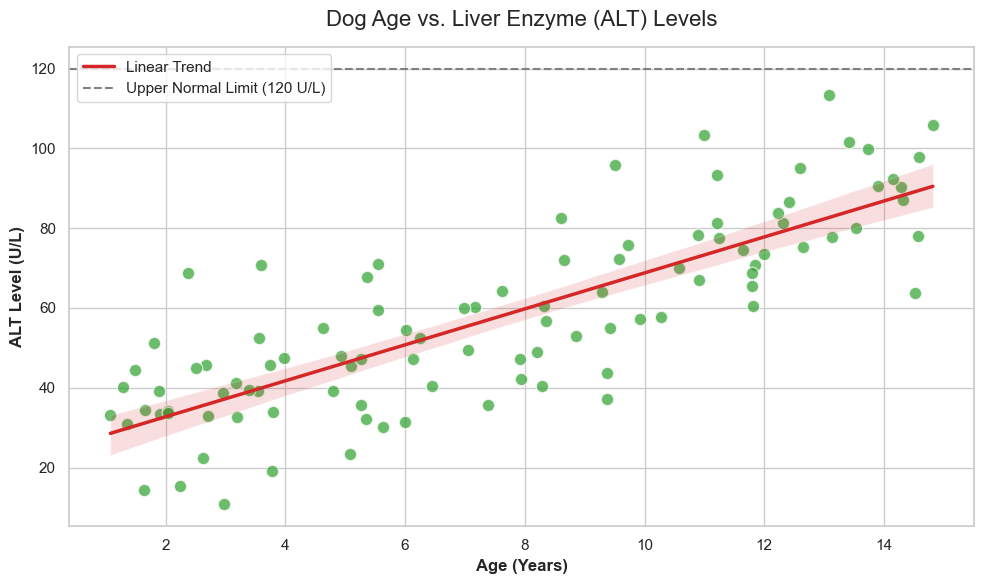

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Generate test data: Dog Age (Years) vs. ALT (U/L)
np.random.seed(42)
ages = np.random.uniform(1, 15, 100) # 100 dogs aged between 1 and 15 years

# Simulate a positive linear relationship with some random biological variance
# Base ALT of ~20, increases by ~5 units per year of age, plus random scatter
alt_levels = 20 + (5 * ages) + np.random.normal(loc=0, scale=15, size=100)

# Ensure no negative ALT levels (biologically impossible)
alt_levels = np.clip(alt_levels, 10, None)

df = pd.DataFrame({
    'Age_Years': ages, 
    'ALT_Level_UL': alt_levels
})

# 2. Set up the visualization style
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# 3. Create the scatter plot with a linear regression line
# sns.regplot automatically plots the scatter points and fits a linear trendline with a 95% confidence interval
sns.regplot(
    data=df, 
    x='Age_Years', 
    y='ALT_Level_UL',
    scatter_kws={'alpha': 0.7, 'color': '#2ca02c', 'edgecolor': 'w', 's': 80},
    line_kws={'color': '#d62728', 'linewidth': 2.5, 'label': 'Linear Trend'}
)

# 4. Customize labels and titles
plt.title('Dog Age vs. Liver Enzyme (ALT) Levels', fontsize=16, pad=15)
plt.xlabel('Age (Years)', fontsize=12, fontweight='bold')
plt.ylabel('ALT Level (U/L)', fontsize=12, fontweight='bold')

# Add a horizontal dashed line showing a typical upper normal limit for context (~120 U/L)
plt.axhline(120, color='gray', linestyle='--', linewidth=1.5, label='Upper Normal Limit (120 U/L)')

plt.legend(loc='upper left')

# 5. Display the plot
plt.tight_layout()
plt.show()